# Clasificación: Random Forest

### Imports y Configuración

In [1]:
import sys
sys.path.append("/workspace/src")

import pandas as pd
import matplotlib.pyplot as plt

from EstiloGraficos import aplicar_estilo

# Misma paleta y estilo que el dashboard (components/plotly_theme.py)
aplicar_estilo()

# Textos largos completos en las tablas (criterio de selección, hiperparámetros)
pd.set_option("display.max_colwidth", None)

from Modelado import (
    SEED, USAR_GPU, GPU_DISPOSITIVOS, NOMBRES_CLF, ESTRATEGIAS, N_ITER_FASE1,
    cargar_split, separar_x_y, crear_cv, dispositivo_modelo, verificar_smotenc,
    describir_espacio, ejecutar_fase1, formatear_tabla_cv, graficar_estrategias, elegir_mejor, guardar_fase1,
    formatear_hiperparametros, tabla_hiperparametros,
)

CLAVE = "random_forest"

In [2]:
pd.Series({
    "USAR_GPU": USAR_GPU,
    "GPU detectada por librería": ", ".join(f"{lib}: {disp}" for lib, disp in GPU_DISPOSITIVOS.items() if disp) or "ninguna",
    "Dispositivo de entrenamiento": dispositivo_modelo(CLAVE),
}, name=NOMBRES_CLF[CLAVE]).to_frame()

,Random Forest
USAR_GPU,False
GPU detectada por librería,ninguna
Dispositivo de entrenamiento,CPU


### Datos: Split y Folds

In [3]:
df = pd.read_csv('/workspace/data/raw/screen_time_mental_health.csv')

df_train, _ = cargar_split(df)   # el test no se usa en esta fase
X_train, y_train = separar_x_y(df_train)
cv = crear_cv(SEED)

pd.DataFrame({
    "Filas": [len(X_train)],
    "Predictores": [X_train.shape[1]],
    "Deprimidos": [int(y_train.sum())],
    "Prevalencia": [round(y_train.mean(), 3)],
}, index=pd.Index(["Train"], name="Conjunto"))

,Filas,Predictores,Deprimidos,Prevalencia
Conjunto,,,,
Train,3848,6,630,0.164


### Estrategias de Manejo del Desbalance

| Estrategia | Qué hace | En Random Forest |
|---|---|---|
| **a) Nativo** | Sin balanceo: el modelo ve la proporción real (16% de positivos). | — |
| **b) Pesos de clase** | Los errores en la clase minoritaria pesan más al entrenar. | `class_weight="balanced_subsample"` (los pesos se recalculan en la muestra *bootstrap* de cada árbol) |
| **c) SMOTENC** | Genera deprimidos sintéticos a partir de sus vecinos deprimidos más cercanos, hasta igualar las clases. Sin pesos de clase. | `SMOTENC(categorical_features=["sex"], random_state=42)` |

In [4]:
tabla_clases, tabla_sexo = verificar_smotenc(X_train, y_train, seed=SEED)
display(tabla_clases)
display(tabla_sexo)

✓ sex solo toma los valores ['Boy', 'Girl']
✓ Clases balanceadas: {0: 3218, 1: 3218}


,Antes,Después,Sintéticos
Deprimido,,,
0,3218,3218,0
1,630,3218,2588


Deprimido,0,1
Sexo,,
Boy,1789,770
Girl,1429,2448


### Espacio de Búsqueda

Se exploraron 25 combinaciones aleatorias por estrategia. Se variaron el número de árboles (200 a 800), su complejidad (profundidad máxima de 3, 5, 8, 12 o sin límite, y un mínimo de 5, 10, 20 o 50 observaciones por hoja) y la fracción de variables candidatas en cada división (`sqrt`, 0.5 o todas).

In [5]:
describir_espacio(CLAVE).style.set_caption(f"Combinaciones por estrategia: {N_ITER_FASE1[CLAVE]}")

,Valores
Hiperparámetro,
n_estimators,entero entre 200 y 800
max_depth,"3, 5, 8, 12, None"
min_samples_leaf,"5, 10, 20, 50"
max_features,"sqrt, 0.5, 1.0"


### Validación Cruzada por Estrategia

Para cada estrategia se ejecuta un `RandomizedSearchCV` **solo sobre el train**, con los mismos folds y `scoring` PR-AUC (`average_precision`).

In [6]:
tabla, pipelines, hiperparametros = ejecutar_fase1(CLAVE, X_train, y_train, cv, seed=SEED)

✓ Nativo (sin balanceo)  PR-AUC = 0.3979 ± 0.0559  (28 s)
✓ Pesos de clase         PR-AUC = 0.3883 ± 0.0401  (31 s)
✓ SMOTENC                PR-AUC = 0.3821 ± 0.0285  (41 s)


In [7]:
vista = formatear_tabla_cv(tabla)
vista["Tiempo (s)"] = tabla["Tiempo (s)"].round(0)
vista.rename(index=ESTRATEGIAS)

,PR-AUC,ROC-AUC,Precision,Recall,F1,Accuracy,Tiempo (s)
Estrategia,,,,,,,
Nativo (sin balanceo),0.398 ± 0.056,0.747 ± 0.033,0.599 ± 0.080,0.113 ± 0.006,0.189 ± 0.008,0.842 ± 0.004,28.0
Pesos de clase,0.388 ± 0.040,0.746 ± 0.027,0.324 ± 0.033,0.576 ± 0.052,0.415 ± 0.040,0.734 ± 0.021,31.0
SMOTENC,0.382 ± 0.028,0.734 ± 0.022,0.339 ± 0.020,0.524 ± 0.027,0.411 ± 0.022,0.754 ± 0.011,41.0


Las tres estrategias obtienen una PR-AUC parecida (0.398 ± 0.056, 0.388 ± 0.040 y 0.382 ± 0.028), con desviaciones que se solapan por completo. El nativo tiene la media más alta, pero también la mayor variabilidad entre folds, y SMOTENC la menor. La ROC-AUC es prácticamente la misma con el nativo y con pesos de clase (0.747 ± 0.033 y 0.746 ± 0.027) y algo menor con SMOTENC (0.734 ± 0.022), aunque dentro de la desviación. La capacidad discriminativa existe, pero es modesta.

Las diferencias aparecen en las demás métricas, calculadas con el umbral de 0.5. El nativo tiene la precision más alta (0.599), pero también la más inestable (± 0.080). Su recall de 0.113 ± 0.006 implica que se le escapa casi el 90% de los casos, lo que deja el F1 en 0.189 ± 0.008. Su accuracy de 0.842 ± 0.004 es la más alta, pero apenas supera la de predecir siempre “no deprimido” (1 − 0.164 = 0.836), así que no refleja capacidad predictiva.

El modelo con pesos de clase alcanza un recall de 0.576 ± 0.052 con una precision de 0.324 ± 0.033, y SMOTENC un recall de 0.524 ± 0.027 con una precision de 0.339 ± 0.020. Ambos llegan a un F1 equivalente (0.415 ± 0.040 y 0.411 ± 0.022), y su accuracy baja a 0.734 ± 0.021 y 0.754 ± 0.011 por el aumento de falsos positivos en la clase mayoritaria.

In [8]:
# Mejores hiperparámetros por estrategia
tabla_hiperparametros(hiperparametros)

,max_depth,max_features,min_samples_leaf,n_estimators
Estrategia,,,,
Nativo (sin balanceo),5,0.5,5,601
Pesos de clase,5,0.5,10,585
SMOTENC,8,sqrt,20,220


El nativo y el de pesos de clase eligieron casi la misma configuración: árboles de profundidad 5, la mitad de las variables candidatas en cada división (`max_features=0.5`) y unos 600 árboles; solo difieren en el mínimo de observaciones por hoja (5 y 10). Que, pudiendo llegar a árboles sin límite de profundidad, se prefieran árboles poco profundos sugiere una señal simple, dominada por efectos principales. SMOTENC eligió árboles algo más profundos (8) pero con hojas más grandes (`min_samples_leaf=20`), `max_features="sqrt"` y solo 220 árboles; las hojas más grandes probablemente compensan el ruido de los casos sintéticos.

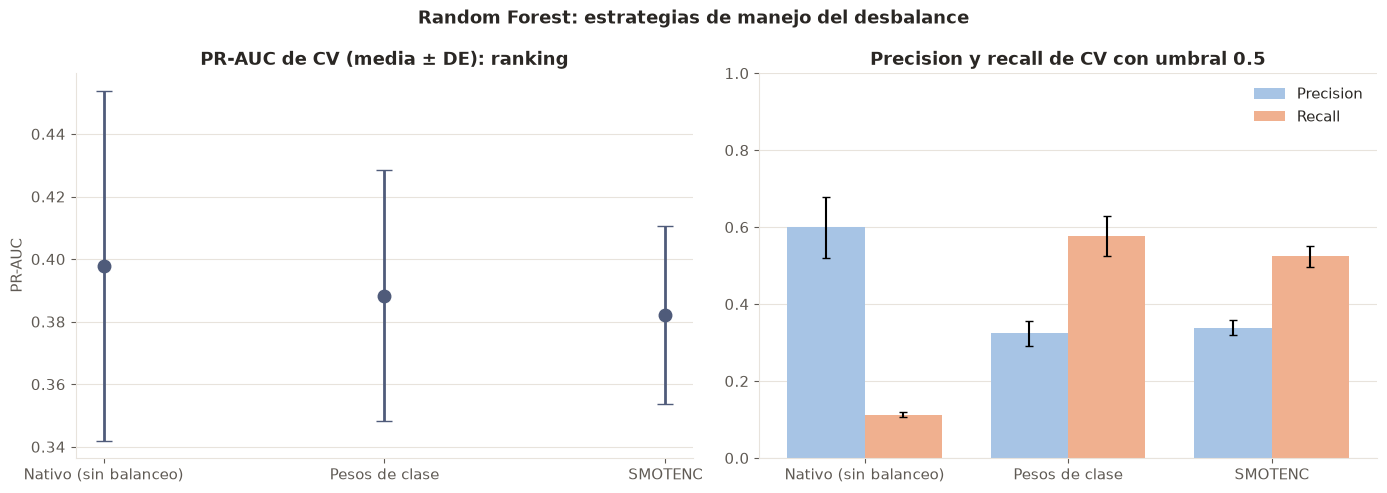

In [9]:
fig = graficar_estrategias(tabla, NOMBRES_CLF[CLAVE])
plt.show()

La gráfica confirma que las tres estrategias producen esencialmente el mismo modelo. La PR-AUC media es muy parecida (~0.38 a ~0.40) y las barras de desviación se solapan casi por completo, así que ni los pesos de clase ni SMOTENC mejoran la capacidad del Random Forest para ordenar los positivos por encima de los negativos. Lo que sí cambia es el comportamiento con el umbral fijo de 0.5. El modelo nativo casi no predice la clase minoritaria, por lo que tiene una precision aceptable (~0.60) pero un recall bajo (~0.11). Los pesos de clase y SMOTENC desplazan el punto de operación hacia más recall (~0.58 y ~0.52) a costa de menos precision (~0.32 y ~0.34).

### Selección del Mejor Modelo Random Forest

Se elige la estrategia con **mayor PR-AUC media de CV**.

In [10]:
estrategia_ganadora, explicacion = elegir_mejor(tabla)

pd.Series({
    "Estrategia ganadora": ESTRATEGIAS[estrategia_ganadora],
    "PR-AUC de CV": f"{tabla.loc[estrategia_ganadora, 'PR-AUC media']:.4f} ± {tabla.loc[estrategia_ganadora, 'PR-AUC DE']:.4f}",
    "Hiperparámetros": formatear_hiperparametros(hiperparametros[estrategia_ganadora]),
    "Criterio": explicacion,
}, name=NOMBRES_CLF[CLAVE]).to_frame()

,Random Forest
Estrategia ganadora,Nativo (sin balanceo)
PR-AUC de CV,0.3979 ± 0.0559
Hiperparámetros,"max_depth=5, max_features=0.5, min_samples_leaf=5, n_estimators=601"
Criterio,Se elige 'nativo': tiene la mayor PR-AUC media de CV (0.3979 ± 0.0559).


Se elige el nativo, que tiene la PR-AUC media más alta (0.3979 ± 0.0559). Su ventaja sobre los pesos de clase (0.0096) y SMOTENC (0.0158) es mucho menor que la desviación entre folds, así que en la práctica las tres estrategias son equivalentes; además, el nativo es la estrategia más variable entre folds. Su recall de 0.113 con umbral 0.5 no es un problema, porque la selección se hace por PR-AUC y el umbral de operación se optimiza en la fase 3.

### Guardado

In [11]:
ganador = guardar_fase1(
    CLAVE, tabla, estrategia_ganadora, pipelines[estrategia_ganadora],
    hiperparametros[estrategia_ganadora], explicacion,
)